# Parameter learning and exact inference

**Ethan — CSE 150A/250A.** Estimate CPTs for the team's frozen Bayesian
network structures, tune smoothing inside the canonical training split,
and export exact $P(\mathrm{popularity}\mid\mathrm{evidence})$ answers for Andrew.

Run from the repository root with the packages in `requirements.txt`.
The reusable implementation is in `parameter_inference.py`. This notebook
runs top to bottom and writes its handoff artifacts to `models/`.
It does not regenerate data, search for graphs, or evaluate `test.csv`.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import hashlib
import importlib.metadata
import json
import platform
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from pgmpy.inference import VariableElimination

from bn_structures import load_split, load_structure, list_structures, state_names, recommended
from parameter_inference import (
    TARGET, SEED, ESS_VALUES, REQUIRED_STRUCTURES, configuration_from_row,
    exact_popularity, fit_parameters, load_fitted_model, make_queries,
    parameter_sweep, popularity_log_probabilities, run_queries,
    save_fitted_model, validate_model, validation_metrics,
)

ROOT = Path.cwd()
assert (ROOT / "models/structures.json").is_file(), "Run from the repository root"
MODEL_DIR = ROOT / "models"
FIG_DIR = ROOT / "figures/parameters"
FIG_DIR.mkdir(parents=True, exist_ok=True)
VERSIONS = {name: importlib.metadata.version(name) for name in
            ["pgmpy", "numpy", "pandas", "scipy", "scikit-learn"]}
print("Python", platform.python_version(), "| Packages", VERSIONS)
assert VERSIONS["pgmpy"] == "1.1.2", "Use the pinned project pgmpy version"

Python 3.12.10 | Packages {'pgmpy': '1.1.2', 'numpy': '2.5.5', 'pandas': '3.1.1', 'scipy': '1.18.1', 'scikit-learn': '1.9.1'}


## Existing data and structures

`data_processing.ipynb` concatenates the high/low popularity sources, drops
duplicate song/artist pairs and missing rows, and bins the remaining features.
Popularity uses five equal-width bins on 0–100; energy, valence, danceability,
and acousticness use five bins on 0–1. Tempo, duration, and release decade use
the custom categories documented in `README.md`. Mode and key are discrete.
We preserve the preprocessing notebook's exact bin labels and boundaries.

`load_split()` removes `name`/`artist` and converts all states to strings.
We discard its test return immediately. `state_names()` reads the already
exported schema, including the full predefined state space. Enumerating this
fixed schema supplies no held-out counts, labels for scoring, or metrics.
No downstream code accesses the test split.

In [2]:
train, unused_test = load_split()
del unused_test
STATES = state_names()
POP_STATES = STATES[TARGET]
assert set(train.columns) == set(STATES)
assert not train.isna().any().any()
for variable in train:
    assert train[variable].isin(STATES[variable]).all()

print(f"Training songs: {len(train):,}; variables: {len(train.columns)}; CV seed: {SEED}")
display(pd.DataFrame({"variable": list(STATES), "states": list(STATES.values())}))
display(train[TARGET].value_counts().reindex(POP_STATES).rename("train_count").to_frame())
print("Available structures:", list_structures())
print("Recommended roles:", recommended())

Training songs: 3,571; variables: 10; CV seed: 150


,variable,states
0,mode,"[0.0, 1.0]"
1,key,"[0.0, 1.0, 10.0, 11.0, 2.0, 3.0, 4.0, 5.0, 6.0..."
2,popularity,"[(-0.001, 20.0], (20.0, 40.0], (40.0, 60.0], (..."
3,energy,"[(-0.001, 0.2], (0.2, 0.4], (0.4, 0.6], (0.6, ..."
4,tempo,"[fast, mid, slow, upbeat]"
5,valence,"[(-0.001, 0.2], (0.2, 0.4], (0.4, 0.6], (0.6, ..."
6,danceability,"[(-0.001, 0.2], (0.2, 0.4], (0.4, 0.6], (0.6, ..."
7,acousticness,"[(-0.001, 0.2], (0.2, 0.4], (0.4, 0.6], (0.6, ..."
8,decade,"[1990s, 2000s, 2010s, 2020s, Before 1990]"
9,duration,"[2-3 min, 3-4 min, 4-5 min, 5+ min, < 2 min]"


,train_count
popularity,
"(-0.001, 20.0]",246
"(20.0, 40.0]",689
"(40.0, 60.0]",1229
"(60.0, 80.0]",1200
"(80.0, 100.0]",207


Available structures: ['Empty graph (prior only)', 'Hand-designed', 'Hand, decade-only pop parent', 'HC + BIC', 'HC popularity-sink', 'HC start=hand', 'HC + AIC', 'HC + K2', 'HC + BDeu(ESS=10)', 'GES (BIC)', 'PC (χ², α=0.01)', 'Chow-Liu tree', 'Naive Bayes', 'TAN', 'HC max-indegree=1', 'HC max-indegree=2', 'HC + BDeu(ESS=1)', 'HC + BDeu(ESS=100)', 'Hand, best 0 pop parent(s)', 'Hand, best 1 pop parent(s)', 'Hand, best 2 pop parent(s)', 'Hand, best 3 pop parent(s)', 'Hand, best 4 pop parent(s)', 'Bootstrap consensus']
Recommended roles: {'main_learned': 'HC + BIC', 'best_bic': 'GES (BIC)', 'proposal': 'Hand-designed', 'best_predictive': 'HC start=hand', 'for_feature_queries': 'HC start=hand', 'note': 'see the Findings section of structure_learning.ipynb'}


In [3]:
# Include the evaluation handoff's GES and Naive Bayes as well as the required three.
STRUCTURES = list(dict.fromkeys([*REQUIRED_STRUCTURES, recommended()["best_bic"], "Naive Bayes"]))
assert set(STRUCTURES).issubset(list_structures())
structure_rows = []
for name in STRUCTURES:
    graph = load_structure(name)
    structure_rows.append({
        "structure": name, "edges": len(graph.edges()),
        "popularity_parents": sorted(graph.get_parents(TARGET)),
        "popularity_children": sorted(graph.get_children(TARGET)),
        "popularity_markov_blanket": sorted(graph.get_markov_blanket(TARGET)),
    })
display(pd.DataFrame(structure_rows))

,structure,edges,popularity_parents,popularity_children,popularity_markov_blanket
0,HC + BIC,9,[decade],[],[decade]
1,HC start=hand,9,[decade],[acousticness],"[acousticness, decade]"
2,Hand-designed,12,"[danceability, decade, energy]",[],"[danceability, decade, energy]"
3,GES (BIC),9,[acousticness],[decade],"[acousticness, decade]"
4,Naive Bayes,9,[],"[acousticness, danceability, decade, duration,...","[acousticness, danceability, decade, duration,..."


## Parameter estimation and validation

For state $x$ and parent configuration $u$, MLE is
$\hat P(x\mid u)=N_{xu}/N_u$. We use pgmpy 1.1.2's `DiscreteMLE`.
For entirely unobserved parent configurations, this implementation chooses a
uniform CPT column; it leaves zeros in otherwise observed columns unchanged.

For BDeu, a node with $r$ states and $q$ parent configurations gets the
Dirichlet pseudocount $\alpha_{xu}=\mathrm{ESS}/(rq)$ in **each** CPT cell:

$$\hat P(x\mid u)=\frac{N_{xu}+\mathrm{ESS}/(rq)}{N_u+\mathrm{ESS}/q}.$$

ESS is the total prior strength per node, not an add-one pseudocount per cell.
We pass an **instance** of `DiscreteBayesianEstimator` to `model.fit` and
always supply the exported state names. All fitted CPTs undergo explicit
normalization checks and `model.check_model()`.

We compare MLE and ESS = 1, 5, 10, 20, 50, 100, 500, 1000. The wider range
allows meaningful smoothing of the hand DAG's larger CPTs. Every candidate
uses the same five stratified folds within `train.csv` (seed 150).

Selection minimizes **unclipped mean validation log loss** for popularity
given the other nine variables. Accuracy and fold standard deviations are
secondary diagnostics. MLE zeros yield infinite loss, and impossible evidence
also disqualifies a candidate; we export a separate loss clipped at $10^{-15}$
for diagnosis, without using it for selection. No probabilities are smoothed
after fitting. CV uses direct exact factor multiplication over the five target
states; later checks compare it against VE.

**Scope:** the learned graphs are fixed exports fitted by the structure stage
using the full training set. This CV tunes parameters conditional on those
graphs; it is not nested CV of structure learning and should not be presented
as an unbiased final generalization estimate. The untouched test evaluation
belongs to Jeslyn.

In [4]:
sweep, fold_scores = parameter_sweep(train, STRUCTURES, ESS_VALUES, n_splits=5, seed=SEED)
assert len(sweep) == len(STRUCTURES) * (1 + len(ESS_VALUES))
assert len(fold_scores) == len(sweep) * 5
sweep.to_csv(MODEL_DIR / "parameter_sweep.csv", index=False)
fold_scores.to_csv(MODEL_DIR / "parameter_cv_folds.csv", index=False)
display(sweep.round(6))

,structure,estimator,equivalent_sample_size,cv_log_loss,cv_log_loss_sd,cv_log_loss_clipped_1e-15,cv_accuracy,cv_accuracy_sd,zero_true_probability_rows,undefined_evidence_rows,n_folds
0,GES (BIC),BDeu,20.0,1.303610,0.003720,1.303610,0.468214,0.008287,0,0,5
1,HC start=hand,BDeu,20.0,1.303610,0.003720,1.303610,0.468214,0.008287,0,0,5
2,GES (BIC),BDeu,10.0,1.303639,0.004134,1.303639,0.468214,0.008287,0,0,5
3,HC start=hand,BDeu,10.0,1.303639,0.004134,1.303639,0.468214,0.008287,0,0,5
4,HC start=hand,BDeu,5.0,1.303766,0.004566,1.303766,0.468214,0.008287,0,0,5
5,GES (BIC),BDeu,5.0,1.303766,0.004566,1.303766,0.468214,0.008287,0,0,5
6,GES (BIC),BDeu,50.0,1.304032,0.003325,1.304032,0.468214,0.008287,0,0,5
7,HC start=hand,BDeu,50.0,1.304032,0.003325,1.304032,0.468214,0.008287,0,0,5
8,GES (BIC),BDeu,1.0,1.304172,0.005574,1.304172,0.467934,0.008270,0,0,5
9,HC start=hand,BDeu,1.0,1.304172,0.005574,1.304172,0.467934,0.008270,0,0,5


In [5]:
eligible = sweep[np.isfinite(sweep.cv_log_loss) & sweep.undefined_evidence_rows.eq(0)]
assert not eligible.empty
TIE_TOLERANCE = 1e-12
minimum_loss = eligible.cv_log_loss.min()
tied = eligible[np.isclose(eligible.cv_log_loss, minimum_loss, atol=TIE_TOLERANCE, rtol=0)]
# Prefer the documented feature-query model when scores differ only by rounding.
preferred = tied[tied.structure.eq(recommended()["for_feature_queries"])]
best = configuration_from_row((preferred if not preferred.empty else tied).iloc[0])
per_structure = {
    name: configuration_from_row(eligible[eligible.structure.eq(name)].iloc[0])
    for name in STRUCTURES
}
print("Selected configuration:", json.dumps(best, indent=2))
display(pd.DataFrame(per_structure.values()).round(6))

mle = sweep[sweep.estimator.eq("MLE")]
display(mle[["structure", "cv_log_loss", "cv_log_loss_clipped_1e-15",
             "zero_true_probability_rows", "undefined_evidence_rows"]])
next_distinct = eligible[eligible.cv_log_loss > minimum_loss + TIE_TOLERANCE].iloc[0]
tie_description = ", ".join(tied.structure.tolist())
display(Markdown(
    f"**Selected: {best['structure']}, {best['estimator']}, ESS={best['equivalent_sample_size']:g}.** "
    f"Its mean CV log loss is **{best['cv_log_loss']:.6f} nats/song** and accuracy is "
    f"**{best['cv_accuracy']:.2%}**. The lowest-loss configurations, tied within "
    f"{TIE_TOLERANCE:g} nats, are **{tie_description}**. We prefer the repository's "
    "recommended feature-query model to break this numerical tie. "
    f"The gap to the next distinct score is {next_distinct.cv_log_loss - minimum_loss:.6f} nats; "
    "small tuning differences should not be interpreted as strong evidence of superiority. "
    "These are training-CV results, not test results."
))
for name, spec in per_structure.items():
    if spec["equivalent_sample_size"] in [min(ESS_VALUES), max(ESS_VALUES)]:
        print(f"Grid boundary: {name} chose ESS={spec['equivalent_sample_size']:g}; "
              "the optimum is only established within the tested grid.")

Selected configuration: {
  "structure": "HC start=hand",
  "estimator": "BDeu",
  "equivalent_sample_size": 20.0,
  "cv_log_loss": 1.3036097692167843,
  "cv_accuracy": 0.46821413880237406
}


,structure,estimator,equivalent_sample_size,cv_log_loss,cv_accuracy
0,HC + BIC,BDeu,10.0,1.330017,0.462617
1,HC start=hand,BDeu,20.0,1.303610,0.468214
2,Hand-designed,BDeu,500.0,1.317643,0.459250
3,GES (BIC),BDeu,20.0,1.303610,0.468214
4,Naive Bayes,BDeu,1000.0,1.358548,0.455055


,structure,cv_log_loss,cv_log_loss_clipped_1e-15,zero_true_probability_rows,undefined_evidence_rows
40,GES (BIC),inf,inf,1,4
41,HC + BIC,inf,inf,1,4
42,HC start=hand,inf,inf,1,4
43,Hand-designed,inf,inf,82,82
44,Naive Bayes,inf,1.384949,1,0


**Selected: HC start=hand, BDeu, ESS=20.** Its mean CV log loss is **1.303610 nats/song** and accuracy is **46.82%**. The lowest-loss configurations, tied within 1e-12 nats, are **GES (BIC), HC start=hand**. We prefer the repository's recommended feature-query model to break this numerical tie. The gap to the next distinct score is 0.000029 nats; small tuning differences should not be interpreted as strong evidence of superiority. These are training-CV results, not test results.

Grid boundary: Naive Bayes chose ESS=1000; the optimum is only established within the tested grid.


## Refit on all training songs and inspect CPTs

Each structure gets its own validation-selected parameters, so the evaluation
teammate can compare the recommended graphs and Naive Bayes using tuned CPTs.
The primary model is the best configuration across the tested structures.
We also retain `HC start=hand` as the documented feature-query model even if
the primary winner changes. The following tables inspect popularity's CPT
for every model; each column is a parent assignment, not a posterior query.

In [6]:
fitted = {}
model_paths = {}
for index, (name, spec) in enumerate(per_structure.items()):
    model = fit_parameters(train, name, spec["estimator"], spec["equivalent_sample_size"])
    fitted[name] = model
    filename = f"parameter_model_{index}.json"
    save_fitted_model(model, MODEL_DIR / filename)
    model_paths[name] = f"models/{filename}"

selected_model = fitted[best["structure"]]
FEATURE_MODEL_ID = recommended()["for_feature_queries"]
feature_model = fitted[FEATURE_MODEL_ID]
checks = pd.concat([validate_model(model).assign(structure=name)
                    for name, model in fitted.items()], ignore_index=True)
display(checks)
for name, model in fitted.items():
    cpd = model.get_cpds(TARGET)
    parents = list(cpd.variables[1:])
    columns = (pd.MultiIndex.from_product([cpd.state_names[p] for p in parents], names=parents)
               if parents else ["marginal"])
    table = pd.DataFrame(cpd.get_values(), index=cpd.state_names[TARGET], columns=columns)
    display(Markdown(f"**{name}:** popularity CPT; parent axes = {parents}"))
    with pd.option_context("display.max_columns", 12):
        display(table.round(5))

print("Feature-model acousticness CPT (a child of popularity, so it also affects the posterior):")
print(feature_model.get_cpds("acousticness"))

,variable,parent_configurations,zero_entries,max_column_sum_error,structure
0,mode,5,0,0.000000e+00,HC + BIC
1,key,2,0,3.330669e-16,HC + BIC
2,popularity,5,0,0.000000e+00,HC + BIC
3,energy,5,0,2.220446e-16,HC + BIC
4,tempo,5,0,0.000000e+00,HC + BIC
5,valence,1,0,0.000000e+00,HC + BIC
6,danceability,5,0,2.220446e-16,HC + BIC
7,acousticness,5,0,3.330669e-16,HC + BIC
8,decade,5,0,1.110223e-16,HC + BIC
9,duration,5,0,4.440892e-16,HC + BIC


**HC + BIC:** popularity CPT; parent axes = ['decade']

decade,1990s,2000s,2010s,2020s,Before 1990
"(-0.001, 20.0]",0.05905,0.03574,0.10676,0.06329,0.00294
"(20.0, 40.0]",0.13524,0.19875,0.23854,0.18897,0.02500
"(40.0, 60.0]",0.17810,0.21755,0.21750,0.46021,0.01029
"(60.0, 80.0]",0.56381,0.48401,0.37807,0.23567,0.83382
"(80.0, 100.0]",0.06381,0.06395,0.05914,0.05186,0.12794


**HC start=hand:** popularity CPT; parent axes = ['decade']

decade,1990s,2000s,2010s,2020s,Before 1990
"(-0.001, 20.0]",0.06038,0.03676,0.10696,0.06342,0.00580
"(20.0, 40.0]",0.13585,0.19875,0.23845,0.18898,0.02754
"(40.0, 60.0]",0.17830,0.21745,0.21746,0.45995,0.01304
"(60.0, 80.0]",0.56038,0.48224,0.37768,0.23563,0.82464
"(80.0, 100.0]",0.06509,0.06480,0.05945,0.05201,0.12899


**Hand-designed:** popularity CPT; parent axes = ['danceability', 'decade', 'energy']

... (3 outputs left out)

**Naive Bayes:** popularity CPT; parent axes = []

,marginal
"(-0.001, 20.0]",0.09757
"(20.0, 40.0]",0.19449
"(40.0, 60.0]",0.31262
"(60.0, 80.0]",0.30628
"(80.0, 100.0]",0.08904


Feature-model acousticness CPT (a child of popularity, so it also affects the posterior):


+-----------------------------+-----+---------------------------+
| popularity                  | ... | popularity((80.0, 100.0]) |
+-----------------------------+-----+---------------------------+
| acousticness((-0.001, 0.2]) | ... | 0.6246445497630331        |
+-----------------------------+-----+---------------------------+
| acousticness((0.2, 0.4])    | ... | 0.12227488151658765       |
+-----------------------------+-----+---------------------------+
| acousticness((0.4, 0.6])    | ... | 0.11753554502369666       |
+-----------------------------+-----+---------------------------+
| acousticness((0.6, 0.8])    | ... | 0.0843601895734597        |
+-----------------------------+-----+---------------------------+
| acousticness((0.8, 1.0])    | ... | 0.051184834123222736      |
+-----------------------------+-----+---------------------------+


## Exact inference experiments

`exact_popularity(model, evidence)` runs `VariableElimination` and returns a
labeled, normalized Series. Evidence can contain any subset of non-target
variables; unknown variables/states and target-as-evidence are rejected.
For MLE models it also checks evidence support before accepting a posterior.

The query list includes the prior, every release-decade category, all five
energy or acousticness categories within each decade, four joint low/high
energy–acousticness combinations per decade, and feature-only partial evidence.
We use the actual state strings from the fitted schema. We run the same list
on every tuned model and export every popularity probability, without rounding.

`train_evidence_count` records the support for each evidence combination.
Rare or unobserved combinations depend heavily on smoothing. These are
observational associations, not causal effects or interventions.

In [7]:
queries = make_queries(STATES)
ve_queries = pd.concat([
    run_queries(model, queries, name, training_data=train)
    for name, model in fitted.items()
], ignore_index=True)
ve_queries.to_csv(MODEL_DIR / "ve_queries.csv", index=False)
assert np.allclose(ve_queries.groupby(["model_id", "query_id"]).probability.sum(), 1,
                   atol=1e-10, rtol=0)
print(f"{len(queries)} evidence configurations x {len(fitted)} models = "
      f"{len(ve_queries) // len(POP_STATES)} normalized distributions")
display(ve_queries.head(15))
print("Example with partial evidence:")
display(exact_popularity(selected_model, {"energy": STATES["energy"][-1]}))

80 evidence configurations x 5 models = 400 normalized distributions


,model_id,query_id,experiment,evidence_json,train_evidence_count,popularity_state,probability
0,HC + BIC,prior,prior,{},3571,"(-0.001, 20.0]",0.069254
1,HC + BIC,prior,prior,{},3571,"(20.0, 40.0]",0.192963
2,HC + BIC,prior,prior,{},3571,"(40.0, 60.0]",0.343759
3,HC + BIC,prior,prior,{},3571,"(60.0, 80.0]",0.335660
4,HC + BIC,prior,prior,{},3571,"(80.0, 100.0]",0.058364
5,HC + BIC,decade_0,decade,"{""decade"": ""1990s""}",208,"(-0.001, 20.0]",0.059048
6,HC + BIC,decade_0,decade,"{""decade"": ""1990s""}",208,"(20.0, 40.0]",0.135238
7,HC + BIC,decade_0,decade,"{""decade"": ""1990s""}",208,"(40.0, 60.0]",0.178095
8,HC + BIC,decade_0,decade,"{""decade"": ""1990s""}",208,"(60.0, 80.0]",0.563810
9,HC + BIC,decade_0,decade,"{""decade"": ""1990s""}",208,"(80.0, 100.0]",0.063810


Example with partial evidence:


(-0.001, 20.0]    0.065940
(20.0, 40.0]      0.174370
(40.0, 60.0]      0.284898
(60.0, 80.0]      0.402133
(80.0, 100.0]     0.072659
Name: probability, dtype: float64

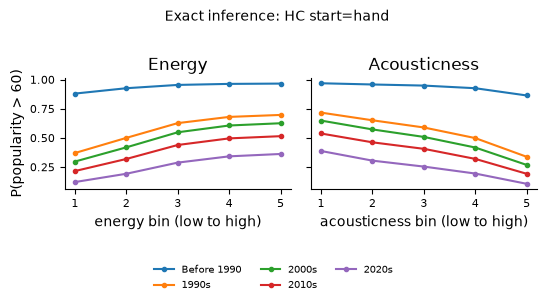

,model_id,decade,feature,low_p_gt_60,high_p_gt_60,high_minus_low,low_train_support,high_train_support
10,HC start=hand,Before 1990,energy,0.87964,0.96538,0.08573,3,52
11,HC start=hand,Before 1990,acousticness,0.96823,0.86350,-0.10473,85,4
12,HC start=hand,1990s,energy,0.36984,0.69654,0.32671,16,55
13,HC start=hand,1990s,acousticness,0.71645,0.33737,-0.37907,115,22
14,HC start=hand,2000s,energy,0.29654,0.62517,0.32863,23,102
15,HC start=hand,2000s,acousticness,0.64811,0.26755,-0.38056,179,41
16,HC start=hand,2010s,energy,0.21509,0.51431,0.29922,54,156
17,HC start=hand,2010s,acousticness,0.53727,0.19166,-0.34562,429,127
18,HC start=hand,2020s,energy,0.12064,0.36161,0.24097,273,351
19,HC start=hand,2020s,acousticness,0.38726,0.10569,-0.28156,855,385


In [8]:
# Summarize the upper two popularity bins, i.e. popularity > 60.
TAIL_STATES = POP_STATES[-2:]
summary = ve_queries[ve_queries.popularity_state.isin(TAIL_STATES)].groupby(
    ["model_id", "query_id", "experiment", "evidence_json", "train_evidence_count"],
    as_index=False,
).probability.sum().rename(columns={"probability": "p_popularity_gt_60"})
summary["evidence"] = summary.evidence_json.map(json.loads)

DECADES = [s for s in ["Before 1990", "1990s", "2000s", "2010s", "2020s"] if s in STATES["decade"]]
fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.9), sharey=True)
for ax, feature in zip(axes, ["energy", "acousticness"]):
    for decade in DECADES:
        group = summary[(summary.model_id == FEATURE_MODEL_ID) & (summary.experiment == feature)]
        by_state = {row.evidence[feature]: row.p_popularity_gt_60
                    for row in group.itertuples() if row.evidence["decade"] == decade}
        ax.plot(range(1, len(STATES[feature]) + 1),
                [by_state[s] for s in STATES[feature]], marker="o", markersize=3, label=decade)
    ax.set(xlabel=f"{feature} bin (low to high)", xticks=range(1, 6), title=feature.capitalize())
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=8)
axes[0].set_ylabel("P(popularity > 60)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=7, frameon=False)
fig.suptitle(f"Exact inference: {FEATURE_MODEL_ID}", fontsize=10)
fig.tight_layout(rect=(0, 0.17, 1, 0.97))
fig.savefig(FIG_DIR / "feature_queries.png", dpi=250)
plt.show()

contrasts = []
for name in fitted:
    for decade in DECADES:
        for feature in ["energy", "acousticness"]:
            group = summary[(summary.model_id == name) & (summary.experiment == feature)]
            rows = [r for r in group.itertuples() if r.evidence["decade"] == decade]
            by_state = {r.evidence[feature]: r for r in rows}
            low, high = by_state[STATES[feature][0]], by_state[STATES[feature][-1]]
            contrasts.append({"model_id": name, "decade": decade, "feature": feature,
                              "low_p_gt_60": low.p_popularity_gt_60,
                              "high_p_gt_60": high.p_popularity_gt_60,
                              "high_minus_low": high.p_popularity_gt_60 - low.p_popularity_gt_60,
                              "low_train_support": low.train_evidence_count,
                              "high_train_support": high.train_evidence_count})
contrasts = pd.DataFrame(contrasts)
display(contrasts[contrasts.model_id.eq(FEATURE_MODEL_ID)].round(5))

In [9]:
feature_contrasts = contrasts[contrasts.model_id.eq(FEATURE_MODEL_ID)]
largest = feature_contrasts.loc[feature_contrasts.high_minus_low.abs().idxmax()]
display(Markdown(
    f"In **{FEATURE_MODEL_ID}**, the largest endpoint change in P(popularity > 60) "
    f"is {largest.high_minus_low:+.3f} for **{largest.feature}** in **{largest.decade}** "
    f"(low bin {largest.low_p_gt_60:.3f}, high bin {largest.high_p_gt_60:.3f}; "
    f"training support {largest.low_train_support} and {largest.high_train_support}). "
    "The table and plot show how the association varies by decade. "
    "The graph links energy to popularity through acousticness; correlated features "
    "can shift predictions without being direct popularity parents."
))

# Graph-implied checks: HC+BIC ignores audio once decade is observed.
for decade in STATES["decade"]:
    reference = exact_popularity(fitted["HC + BIC"], {"decade": decade})
    for feature in ["energy", "acousticness"]:
        for category in STATES[feature]:
            actual = exact_popularity(fitted["HC + BIC"], {"decade": decade, feature: category})
            np.testing.assert_allclose(actual, reference, atol=1e-12, rtol=0)

# In HC start=hand, observing acousticness blocks the energy-popularity path.
for decade in STATES["decade"]:
    for acousticness in [STATES["acousticness"][0], STATES["acousticness"][-1]]:
        evidence = {"decade": decade, "acousticness": acousticness}
        reference = exact_popularity(feature_model, evidence)
        for energy in [STATES["energy"][0], STATES["energy"][-1]]:
            np.testing.assert_allclose(exact_popularity(feature_model, evidence | {"energy": energy}),
                                       reference, atol=1e-12, rtol=0)
print("Verified both graph-implied conditional independences.")

In **HC start=hand**, the largest endpoint change in P(popularity > 60) is -0.381 for **acousticness** in **2000s** (low bin 0.648, high bin 0.268; training support 179 and 41). The table and plot show how the association varies by decade. The graph links energy to popularity through acousticness; correlated features can shift predictions without being direct popularity parents.

Verified both graph-implied conditional independences.


## Reusable artifacts and checks

`parameter_config.json` identifies the primary model and the best parameters
and fitted-model path for each structure. It includes the full query list,
state order, package versions, and hashes of the frozen training/structure
inputs. Models are portable JSON, with every CPT's state labels and axis order
preserved; `load_fitted_model` restores a normal pgmpy network.

`ve_queries.csv` is in long form: filter by `model_id` and `query_id`, decode
`evidence_json`, and compare sampling estimates with the rows indexed by
`popularity_state`. Do not assume integer state indices mean numeric popularity
values: always use the exported state order. Reuse the same fitted model and
clamp the same evidence when comparing Gibbs to VE.

In [10]:
config = {
    "format_version": 1,
    **best,
    "target": TARGET,
    "primary_model_id": best["structure"],
    "feature_query_model_id": FEATURE_MODEL_ID,
    "model_path": model_paths[best["structure"]],
    "per_structure": {name: spec | {"model_path": model_paths[name]}
                      for name, spec in per_structure.items()},
    "equivalent_sample_sizes_tested": list(ESS_VALUES),
    "selection_metric": "mean_unclipped_validation_popularity_log_loss_nats",
    "selection_tie_tolerance": TIE_TOLERANCE,
    "selection_tie_break": "prefer recommended for_feature_queries model within numerical tolerance",
    "tied_best_configurations": [configuration_from_row(row) for _, row in tied.iterrows()],
    "selection_scope": "parameter CV conditional on frozen exported graphs; not nested structure CV",
    "cv": {"method": "StratifiedKFold", "n_splits": 5, "shuffle": True, "random_state": SEED},
    "training_rows": len(train),
    "test_used_for_fitting_or_selection": False,
    "state_names": STATES,
    "train_sha256": hashlib.sha256((ROOT / "data/train.csv").read_bytes()).hexdigest(),
    "structures_sha256": hashlib.sha256((MODEL_DIR / "structures.json").read_bytes()).hexdigest(),
    "package_versions": VERSIONS,
    "query_specs": queries,
    "ve_results_path": "models/ve_queries.csv",
    "mle_zero_policy": "Zero true-class probability gives infinite loss; impossible evidence disqualifies candidate",
    "clipped_diagnostic_floor": 1e-15,
}
(MODEL_DIR / "parameter_config.json").write_text(
    json.dumps(config, indent=2, allow_nan=False) + "\n", encoding="utf-8")

19191

In [11]:
# Independently compare the vectorized exact predictor with pgmpy VE.
sample = train.sample(n=6, random_state=SEED)
for name, model in fitted.items():
    predictions = np.exp(popularity_log_probabilities(model, sample.drop(columns=TARGET)))
    for position, (_, row) in enumerate(sample.iterrows()):
        posterior = exact_popularity(model, row.drop(TARGET).to_dict())
        np.testing.assert_allclose(predictions[position], posterior, atol=1e-12, rtol=1e-12)

# Verify a BDeu CPT against the count formula, independent of pgmpy's estimator.
bdeu_model = fit_parameters(train, "HC + BIC", "BDeu", 5)
cpd = bdeu_model.get_cpds(TARGET)
decade = STATES["decade"][0]
counts = train.loc[train.decade.eq(decade), TARGET].value_counts().reindex(POP_STATES, fill_value=0)
expected = (counts.to_numpy() + 5 / (len(POP_STATES) * len(STATES["decade"]))) / (
    counts.sum() + 5 / len(STATES["decade"]))
np.testing.assert_allclose(cpd.get_values()[:, cpd.state_names["decade"].index(decade)], expected)

# An MLE fit on one real song creates zero-probability feature evidence.
# Confirm that evidence pruned away by VE is still rejected by our API.
sparse_train = train.iloc[[0]]
sparse_mle = fit_parameters(sparse_train, "HC start=hand", "MLE", None)
unseen_key = next(s for s in STATES["key"] if s != sparse_train.iloc[0]["key"])
try:
    exact_popularity(sparse_mle, {"mode": sparse_train.iloc[0]["mode"], "key": unseen_key})
    raise AssertionError("Impossible MLE evidence was accepted")
except ValueError as error:
    assert "zero probability" in str(error)
metrics = validation_metrics(sparse_mle, train.iloc[1:40])
assert metrics["undefined_evidence_rows"] > 0 and np.isinf(metrics["log_loss"])

for invalid_evidence in [{"unknown_feature": "bad"}, {"energy": "high"}, {TARGET: POP_STATES[0]}]:
    try:
        exact_popularity(selected_model, invalid_evidence)
        raise AssertionError("Invalid evidence was accepted")
    except ValueError:
        pass

# Reload every model and reproduce every exported query, including partial evidence.
for name, path in model_paths.items():
    restored = load_fitted_model(ROOT / path)
    for original_cpd in fitted[name].get_cpds():
        loaded_cpd = restored.get_cpds(original_cpd.variable)
        assert loaded_cpd.state_names == original_cpd.state_names
        np.testing.assert_array_equal(loaded_cpd.values, original_cpd.values)
    reproduced = run_queries(restored, queries, name, training_data=train)
    original = ve_queries[ve_queries.model_id.eq(name)].reset_index(drop=True)
    pd.testing.assert_frame_equal(reproduced, original, check_exact=False, atol=1e-12, rtol=1e-12)

loaded_config = json.loads((MODEL_DIR / "parameter_config.json").read_text(encoding="utf-8"))
assert loaded_config["query_specs"] == queries
saved_queries = pd.read_csv(MODEL_DIR / "ve_queries.csv")
assert len(saved_queries) == len(fitted) * len(queries) * len(POP_STATES)
assert not saved_queries.duplicated(["model_id", "query_id", "popularity_state"]).any()
assert np.allclose(saved_queries.groupby(["model_id", "query_id"]).probability.sum(), 1,
                   atol=1e-10, rtol=0)
assert len(pd.read_csv(MODEL_DIR / "parameter_sweep.csv")) == len(sweep)
assert len(pd.read_csv(MODEL_DIR / "parameter_cv_folds.csv")) == len(fold_scores)
print("Passed: CPT checks, BDeu count formula, exact predictor vs VE, MLE zero handling,")
print("invalid evidence, all model round trips, all exported query answers, and artifact schemas.")

Passed: CPT checks, BDeu count formula, exact predictor vs VE, MLE zero handling,
invalid evidence, all model round trips, all exported query answers, and artifact schemas.


## Team usage

Load the trained model once, without fitting again:

```python
import json
import pandas as pd
from parameter_inference import load_fitted_model, exact_popularity

config = json.load(open("models/parameter_config.json"))
model = load_fitted_model(config["model_path"])
query = next(q for q in config["query_specs"] if q["query_id"] != "prior")
posterior = exact_popularity(model, query["evidence"])
answers = pd.read_csv("models/ve_queries.csv")
reference = answers[(answers.model_id == config["primary_model_id"]) &
                    (answers.query_id == query["query_id"])].set_index("popularity_state").probability
```

Andrew: use `query["evidence"]` and this exact model for conditional Gibbs
sampling, and compare in `config["state_names"]["popularity"]` order.
The prior query uses an empty evidence dictionary. Feature-query comparisons
can instead use `config["feature_query_model_id"]` and its `per_structure`
model path. Each CSV row identifies its model; answers from different models
are not interchangeable.

Jeslyn: `config["per_structure"]` provides tuned models for `HC + BIC`,
`HC start=hand`, `Hand-designed`, `GES (BIC)`, and `Naive Bayes`.
Your stage owns the first held-out test evaluation, confusion matrices, and
official performance claims. No Gibbs sampler or final test evaluation is
implemented here. `figures/parameters/feature_queries.png` is 5.5 inches wide
for the report. Rerunning this notebook replaces only this stage's artifacts.